# ULTIMATE–Subaru | TNG50-SKIRT dust pilot

**Galaxy:** TNG50 subhalo **294866**, orientation **O1**, atlas **DR1** (not DR2).  
**Goal:** Compare attenuation in optical **LSST g** and NIR **2MASS Ks** with the simulation's projected dust surface-density map. This is a **one-galaxy demonstration**, not a machine-learning or ULTIMATE feasibility result.

**Where to run:** Save this notebook in `~/ULTIMATE/TNG50_SKIRT/` on the remote server. Put all five FITS files in the existing `pilot_294866/` folder. Outputs go to `results/` (input files are not modified).

**Required packages:** `numpy`, `scipy`, `matplotlib`. Notebook uses a small FITS reader for this *verified single-HDU 2D float32 input format*, so `astropy` is not required for this exact pilot. Use `astropy.io.fits` for general FITS analysis.

## Key findings from the uploaded data

- Full-frame flux-weighted effective attenuation: **g ≈ 0.334 mag**, **Ks ≈ 0.021 mag**.
- Within the central 20 kpc, 1-kpc binned Spearman association between **projected dust surface density** and **effective attenuation**: **g ≈ 0.924**, **Ks ≈ 0.548** (1,264 spatial bins).
- Spatial bins within a single simulated galaxy are *not independent galaxies*. Association here is expected in a physically constructed radiative-transfer simulation, and alone does **not** demonstrate recovering 3D dust geometry from observations.


## Context & methods

At each spatial location, define $A_\lambda=-2.5\log_{10}(I_{\lambda,\mathrm{dust}}/I_{\lambda,\mathrm{nodust}})$. These are *effective* attenuation maps: scattering can produce locally negative values.

**Key assumptions:** Corresponding dust/no-dust maps are co-registered and have identical surface-brightness units and physical pixel scale. Spatial values are averaged **before** ratios. We show the central $40\times40$ kpc, smooth to 0.5 kpc for map display, and use 1 kpc bins within a circular 20 kpc radius for correlation. The faint surface-brightness threshold and 20 kpc aperture are exploratory selections, not optimized. Spatial bins are correlated and are not independent galaxy samples.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.stats import spearmanr

# Works when placed in ~/ULTIMATE/TNG50_SKIRT with pilot_294866 as a subfolder.
ROOT = Path.cwd()
DATA_DIR = ROOT / "pilot_294866"
if not DATA_DIR.is_dir():
    DATA_DIR = ROOT   # Also supports the five FITS files beside the notebook.
OUTPUT = ROOT / "results"
OUTPUT.mkdir(exist_ok=True)

# Lightweight FITS loader for these verified single-HDU 2D floating-point files.
# If working with other FITS products, use astropy.io.fits instead.
def load_simple_fits(path):
    with open(path, 'rb') as f:
        header = b''
        while True:
            block = f.read(2880)
            if len(block) != 2880:
                raise ValueError(f'Incomplete FITS header: {path}')
            header += block
            if any(block[i:i+8].strip() == b'END' for i in range(0, 2880, 80)):
                break
        cards = [header[i:i+80].decode('ascii') for i in range(0, len(header), 80)]
        values = {}
        for card in cards:
            if card[8:10] == '= ':
                raw = card[10:80].strip()
                values[card[:8].strip()] = (raw.split("'",2)[1] if raw.startswith("'") else raw.split('/')[0].strip()).strip()
        nx = int(values['NAXIS1']); ny = int(values['NAXIS2'])
        if int(values['BITPIX']) != -32 or int(values['NAXIS']) != 2:
            raise ValueError(f'Expected 2D float32 FITS: {path}')
        image = np.fromfile(f, dtype='>f4', count=nx*ny)
        if image.size != nx*ny:
            raise ValueError(f'Incomplete FITS image: {path}')
        return image.reshape(ny, nx).astype(np.float64), values

base = 'TNG294866_O1_'
files = {
    'g': 'LSST_g', 'g0': 'LSST_g_nodust',
    'ks': '2MASS_Ks', 'ks0': '2MASS_Ks_nodust',
    'dust': 'dustmass'
}
data, headers = {}, {}
for name, suffix in files.items():
    data[name], headers[name] = load_simple_fits(DATA_DIR / f'{base}{suffix}.fits')

assert all(x.shape == (1600, 1600) for x in data.values())
assert all(headers[n]['BUNIT'] == 'MJy/sr' for n in ('g','g0','ks','ks0'))
assert headers['dust']['BUNIT'] == 'Msun/pc2'
assert all(float(headers[n]['CDELT1']) == 100 for n in data)
print('Loaded all five 1600 x 1600 FITS files (100 pc per pixel).')


Loaded all five 1600 x 1600 FITS files (100 pc per pixel).


## Data checks and measurements

In [2]:
def block_mean(arr, b):
    ny, nx = arr.shape
    assert ny % b == 0 and nx % b == 0
    return arr.reshape(ny//b, b, nx//b, b).mean(axis=(1, 3))

def effective_attenuation(dusty, dustfree):
    result = np.full(dusty.shape, np.nan, dtype=float)
    ok = (dusty > 0) & (dustfree > 0)
    result[ok] = -2.5 * np.log10(dusty[ok] / dustfree[ok])
    return result

# Integral of surface brightness is proportional to integrated flux because
# pixels have identical physical area in each map.
def integrated_attenuation(dusty, dustfree):
    good = np.isfinite(dusty) & np.isfinite(dustfree)
    return -2.5*np.log10(dusty[good].sum()/dustfree[good].sum())

a_g_total=integrated_attenuation(data['g'], data['g0'])
a_k_total=integrated_attenuation(data['ks'], data['ks0'])
print(f'Whole-image integrated attenuation: g = {a_g_total:.4f} mag, Ks = {a_k_total:.4f} mag')

# For the maps, aggregate to 0.5 kpc bins before taking brightness ratios.
b_map = 5
maps = {n: block_mean(a, b_map) for n,a in data.items()}
Ag_map = effective_attenuation(maps['g'], maps['g0'])
Ak_map = effective_attenuation(maps['ks'], maps['ks0'])

# For the quantitative comparison, aggregate to 1 kpc bins.
b_stat = 10
binned = {n: block_mean(a, b_stat) for n,a in data.items()}
Ag = effective_attenuation(binned['g'], binned['g0'])
Ak = effective_attenuation(binned['ks'], binned['ks0'])
ys, xs = np.indices(Ag.shape)
scale_kpc = 0.1 * b_stat
radius_kpc = np.hypot((xs+.5 - 800/b_stat)*scale_kpc,
                      (ys+.5 - 800/b_stat)*scale_kpc)
mask = ((radius_kpc < 20) & (binned['dust'] > 0) &
        (binned['g0'] > 1e-4 * binned['g0'].max()) &
        (binned['ks0'] > 1e-4 * binned['ks0'].max()) &
        np.isfinite(Ag) & np.isfinite(Ak))
log_sigma = np.log10(binned['dust'][mask])
rho_g = spearmanr(log_sigma, Ag[mask]).statistic
rho_ks = spearmanr(log_sigma, Ak[mask]).statistic
print(f'Central R<20 kpc, 1-kpc bins: N = {mask.sum()}')
print(f'Spearman rho(log Sigma_dust, A_g) = {rho_g:.3f}')
print(f'Spearman rho(log Sigma_dust, A_Ks) = {rho_ks:.3f}')
print('These are descriptive associations within ONE simulated galaxy, not independent-galaxy statistics.')


Whole-image integrated attenuation: g = 0.3344 mag, Ks = 0.0206 mag
Central R<20 kpc, 1-kpc bins: N = 1264
Spearman rho(log Sigma_dust, A_g) = 0.924
Spearman rho(log Sigma_dust, A_Ks) = 0.548
These are descriptive associations within ONE simulated galaxy, not independent-galaxy statistics.


## Results — with-dust vs dust-free images

Each row uses the **same stretch** in its two panels; the optical and NIR rows have separate scales. The comparison is for the same physical field.

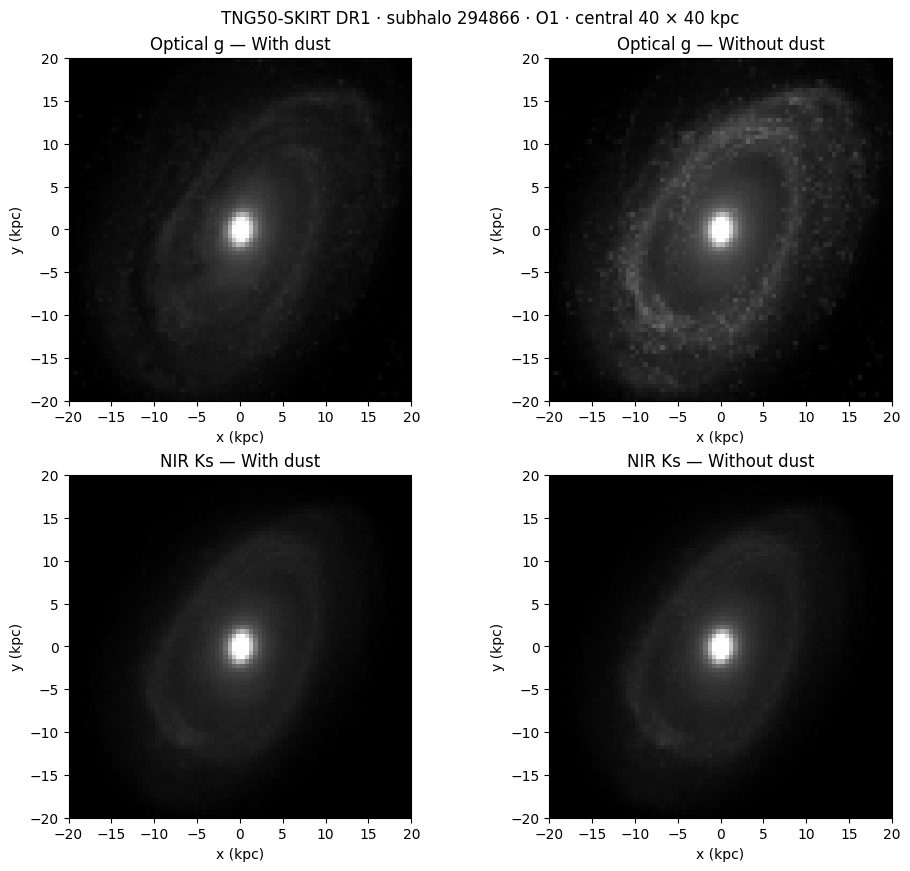

In [3]:
# Figure 1: matched fields with and without dust, by band.
# Shared stretch within each band makes visual comparison meaningful.
from matplotlib.colors import Normalize

b = b_map  # 0.5 kpc display pixels
mid = 800 // b
half = int(20 / (0.1 * b))  # 20 kpc half width
s = np.s_[mid-half:mid+half, mid-half:mid+half]
images = [(maps['g'][s], maps['g0'][s], 'Optical g'),
          (maps['ks'][s], maps['ks0'][s], 'NIR Ks')]
fig, axes = plt.subplots(2, 2, figsize=(9.6, 8.6), constrained_layout=True)
for row, (dusty, dustfree, label) in enumerate(images):
    valid = np.concatenate([dusty[np.isfinite(dusty)], dustfree[np.isfinite(dustfree)]])
    high = np.percentile(valid, 99.8)
    low = max(high * 0.005, 1e-30)
    # asinh compresses high dynamic range; within-band parameters match exactly.
    transform = lambda arr: np.arcsinh(np.maximum(arr, 0) / (high / 12))
    lo, hi = transform(low), transform(high)
    for col, (arr, status) in enumerate([(dusty, 'With dust'), (dustfree, 'Without dust')]):
        ax = axes[row, col]
        ax.imshow(transform(arr), origin='lower', extent=(-20,20,-20,20),
                  cmap='gray', vmin=lo, vmax=hi, interpolation='nearest')
        ax.set_title(f'{label} — {status}')
        ax.set(xlabel='x (kpc)', ylabel='y (kpc)')
        ax.set_aspect('equal')
fig.suptitle('TNG50-SKIRT DR1 · subhalo 294866 · O1 · central 40 × 40 kpc', fontsize=12)
fig.savefig(OUTPUT / 'TNG294866_optical_nir_dust_vs_nodust.png', dpi=180, bbox_inches='tight')
plt.show()


## Results — spatial maps

Note different color scales for g and Ks: near-infrared attenuation is smaller in amplitude. Color-map ranges are for visualization and clip some extrema. Use matching coordinates and inspect masked or very faint pixels before drawing physical conclusions.

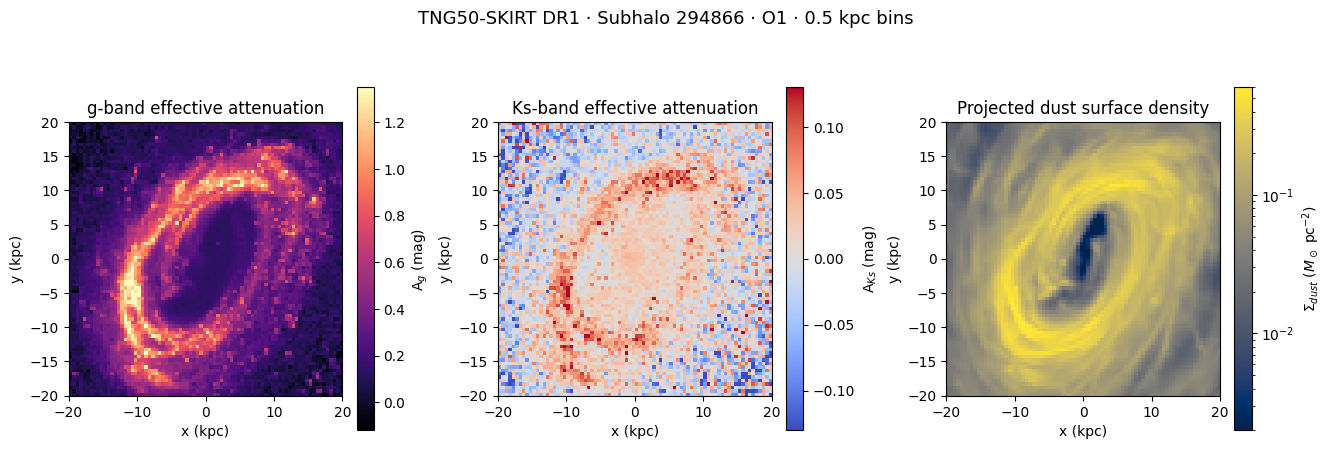

In [4]:
# Plot identical 40 x 40 kpc fields, binned to 0.5 kpc resolution.
# Physical x and y coordinates are measured relative to the image centre.
mid = 800 // b_map
half = int(20 / (0.1 * b_map))
sl = np.s_[mid-half:mid+half, mid-half:mid+half]
region_dust = maps['dust'][sl]
visible = ((maps['g0'][sl] > 1e-4*maps['g0'].max()) &
           (maps['ks0'][sl] > 1e-4*maps['ks0'].max()))
Ag_img = np.ma.masked_where(~visible | ~np.isfinite(Ag_map[sl]), Ag_map[sl])
Ak_img = np.ma.masked_where(~visible | ~np.isfinite(Ak_map[sl]), Ak_map[sl])
d_img = np.ma.masked_where(~(region_dust > 0), region_dust)

fig, axes = plt.subplots(1,3,figsize=(13.2,4.8), constrained_layout=True)
extent=(-20,20,-20,20)
plot_args = dict(origin='lower', extent=extent, interpolation='nearest')
im0=axes[0].imshow(Ag_img, cmap='magma', vmin=-0.12, vmax=1.35, **plot_args)
im1=axes[1].imshow(Ak_img, cmap='coolwarm', norm=TwoSlopeNorm(vmin=-0.13,vcenter=0,vmax=0.13), **plot_args)
im2=axes[2].imshow(d_img, cmap='cividis', norm=LogNorm(vmin=0.002,vmax=0.6), **plot_args)
for ax, title in zip(axes, ['g-band effective attenuation','Ks-band effective attenuation','Projected dust surface density']):
    ax.set(title=title, xlabel='x (kpc)', ylabel='y (kpc)', xlim=(-20,20),ylim=(-20,20))
    ax.set_aspect('equal')
for ax,im,unit in zip(axes,[im0,im1,im2],['A$_g$ (mag)','A$_{Ks}$ (mag)',r'$\Sigma_{dust}$ ($M_\odot$ pc$^{-2}$)']):
    fig.colorbar(im, ax=ax, shrink=.77, label=unit, pad=.02)
fig.suptitle('TNG50-SKIRT DR1 · Subhalo 294866 · O1 · 0.5 kpc bins', fontsize=13)
fig.savefig(OUTPUT/'TNG294866_dust_structure_maps.png',dpi=210,bbox_inches='tight')
plt.show()


## Results — dust correlation

The plotted Spearman correlations are descriptive within this **single simulated galaxy**. They do not measure generalization to other galaxies, viewing angles, stellar populations, or real instruments. In particular, variation with galactocentric radius could contribute to the trend.

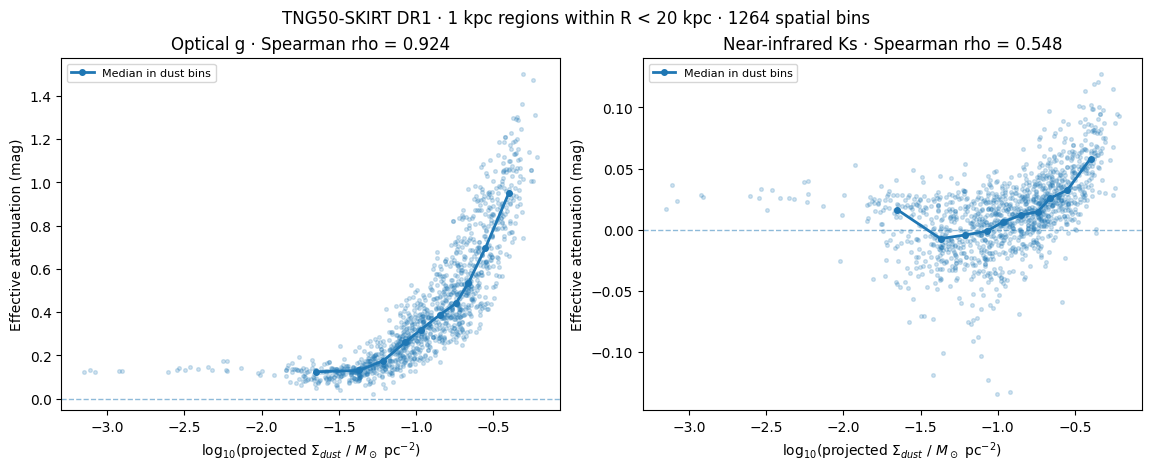

In [5]:
# Compare the same 1 kpc patches, using a radius-limited galaxy region.
fig, axes = plt.subplots(1,2,figsize=(11.4,4.6),constrained_layout=True)
for ax, y, title in [(axes[0],Ag[mask], 'Optical g'), (axes[1], Ak[mask], 'Near-infrared Ks')]:
    rho = spearmanr(log_sigma, y).statistic
    ax.scatter(log_sigma,y,s=7,alpha=.2,rasterized=True)
    edges=np.quantile(log_sigma,np.linspace(0,1,11))
    middles=[]; medians=[]
    for low,high in zip(edges[:-1],edges[1:]):
        mm=(log_sigma>=low)&(log_sigma<high if high!=edges[-1] else log_sigma<=high)
        if mm.sum():
            middles.append(np.median(log_sigma[mm])); medians.append(np.median(y[mm]))
    ax.plot(middles,medians,marker='o',markersize=4,lw=2,label='Median in dust bins')
    ax.axhline(0,linestyle='--',linewidth=1,alpha=.5)
    ax.set(xlabel=r'log$_{10}$(projected $\Sigma_{dust}$ / $M_\odot$ pc$^{-2}$)',
           ylabel='Effective attenuation (mag)',title=f'{title} · Spearman rho = {rho:.3f}')
    ax.legend(loc='upper left',fontsize=8)
fig.suptitle(f'TNG50-SKIRT DR1 · 1 kpc regions within R < 20 kpc · {mask.sum()} spatial bins',fontsize=12)
fig.savefig(OUTPUT/'TNG294866_dust_attenuation_relationship.png', dpi=210,bbox_inches='tight')
plt.show()


## Interpretation and what to do next

1. **Validation:** These five FITS maps align and permit physically meaningful effective-attenuation maps. The optical g band shows stronger attenuation than Ks for this galaxy.
2. **Immediately next:** Repeat the *same analysis* for orientations **O2–O5**, and compare the correlation coefficients by orientation. Five views of one galaxy still do not count as five independent galaxies.
3. **Independent validation:** Add a small number of *different* TNG50 galaxies before fitting even a simple model. Split train/test **by galaxy**, never by pixel or orientation.
4. **Avoid dust-geometry overclaiming:** Surface density is a 2D projection, and attenuation depends on star–dust geometry, scattering, and stellar populations. Strong correlations within SKIRT are descriptive, not evidence of recovered 3D geometry.
5. **Mock observations:** Forward-model the ideal images through the intended ULTIMATE filter transmission, cosmological distance, appropriate PSF, pixel sampling, sky noise and detector noise; do **not** improve a blurred observed HAWK-I image by convolution. Verify assumptions for the specific instrument configuration.
6. **Presentation:** For a 10-minute workshop talk, show the first comparison, dust/attenuation maps, correlation plots, and one slide explicitly labelled **planned feasibility test**. Explain that the reported results are preliminary and from **one** galaxy / one view.
